# Verificação integral das correções — 12/10/2026

**Matheus Silva Riscado · RM573622 · individual.**

Execução `20261013T005458935971Z`: 15 células concluídas em ordem, sem erros. Os cinco gráficos foram exibidos automaticamente e preservados na exportação. Esta rodada testa as correções de reprodução e não substitui os resultados de referência de 04/10 usados no vídeo. Após exportar, apenas as células Markdown desta cópia foram revisadas; a exportação original está ao lado, sem alterações.

In [1]:
from pathlib import Path
import os, sys, json, csv, hashlib, subprocess, shutil, time, platform, gc
from datetime import datetime, timezone

# Classes escolhidas: manter esta ordem também no Make Sense AI.
CLASSES = ["garrafa", "banana"]
COCO_NAMES = ["bottle", "banana"]  # Correspondência na mesma ordem de CLASSES.
SEED, IMAGE_SIZE, BATCH_SIZE = 42, 640, 8
EPOCHS = [30, 60]
CONFIDENCE, NMS_IOU = 0.25, 0.45
USE_DRIVE = True
DRIVE_ROOT = Path("/content/drive/MyDrive/FarmTechFase6")

# Padrão público já testado em sessão limpa: dispensa montar o Drive e editar caminhos.
# O ZIP contém images/, labels/ e fontes.csv. Para a alternativa com Drive, ver docs/REPRODUCAO.md.
DATASET_ZIP_URL = "https://github.com/teteuriscado-bot/MatheusSilvaRiscado/releases/download/fase6-2026-10-04/DATASET-FARMTECH-FASE6.zip"
YOLOV5_REVISION = "2b1bdcd03663afe204bb614593f78be3facfbcaa"
WORK = Path("/content/farmtech_fase6")
WORK.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
print("Classes:", CLASSES, "| Execução:", RUN_ID)


Classes: ['garrafa', 'banana'] | Execução: 20261013T005458935971Z


## 2. Ambiente desta verificação

Colab Linux, Python 3.13.15, PyTorch 2.11.0+cu130 e Tesla T4; CNN e inferência comparativa em CPU. A instalação usa 28 versões centrais fixas e a mesma revisão YOLOv5 do projeto. O ambiente completo e as dependências efetivamente instaladas foram preservados no ZIP. A reprodução iniciou em uma sessão reiniciada, sem saídas, com dataset público e `USE_DRIVE=True` para preservar resultados. Esta é a única diferença de código em relação ao notebook principal, cujo padrão é `False`. Todas as células foram concluídas do início ao fim, sem alterações intermediárias no código. Figuras grandes têm prévias compactas embutidas; os PNGs completos estão no pacote.

In [2]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = DRIVE_ROOT / "resultados" / RUN_ID
else:
    OUT = WORK / "resultados" / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)

# subprocess com lista de argumentos evita problemas de espaços e expansão de shell.
def run_command(arguments, cwd=None):
    subprocess.run([str(a) for a in arguments], cwd=cwd, check=True)

REPO = WORK / "yolov5"
if not REPO.exists():
    run_command(["git", "clone", "https://github.com/ultralytics/yolov5.git", REPO])
run_command(["git", "checkout", "--detach", YOLOV5_REVISION], cwd=REPO)
# Mesmas versões centrais da rodada de referência. A lista também está em requirements-colab.txt.
# O sufixo CUDA/CPU de torch é preservado quando a versão pública já coincide.
CORE_REQUIREMENTS = """
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
pillow==11.3.0
scipy==1.16.3
seaborn==0.13.2
scikit-learn==1.6.1
torch==2.11.0
torchvision==0.26.0
tensorflow==2.20.0
keras==3.13.2
h5py==3.16.0
ml_dtypes==0.6.0
protobuf==5.29.6
tensorboard==2.20.0
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
albumentations==2.0.8
albucore==0.0.24
ultralytics==8.4.173
ultralytics-thop==2.2.2
ultralytics-platform==0.1.79
PyYAML==6.0.3
psutil==5.9.5
requests==2.32.4
tqdm==4.67.3
packaging==26.3
setuptools==80.10.2
""".strip() + "\n"
requirements_path = OUT / "requirements-colab.txt"
requirements_path.write_text(CORE_REQUIREMENTS, encoding="utf-8")
run_command([sys.executable, "-m", "pip", "install", "-q",
             "-r", REPO / "requirements.txt", "-r", requirements_path])
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(OUT / "requirements-executados.txt").write_text(freeze, encoding="utf-8")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display, Markdown, Image as IPythonImage
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

DEVICE = "0" if torch.cuda.is_available() else "cpu"
environment = {"python": sys.version, "platform": platform.platform(),
               "torch": torch.__version__, "yolov5_revision": YOLOV5_REVISION,
               "training_device": DEVICE, "run_id": RUN_ID,
               "gpu": torch.cuda.get_device_name(0) if DEVICE == "0" else None}
(OUT / "ambiente.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
display(environment)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.grid": True})
EPOCH_COLORS = {30: "#2563a6", 60: "#c17c1f"}


def show_saved_figure(figure, filename, dpi=160):
    # YOLOv5 seleciona o backend Agg; exibir o PNG explicitamente funciona também nesse caso.
    path = OUT / filename
    figure.tight_layout()
    figure.savefig(path, dpi=dpi)
    plt.close(figure)
    # Prévia compacta evita que o Colab externalize fotos grandes na exportação.
    # O PNG em resolução completa permanece preservado no pacote de resultados.
    inline_path = path
    if path.stat().st_size > 400_000:
        inline_path = path.with_name(path.stem + "_preview.jpg")
        with Image.open(path) as original:
            preview = original.convert("RGB")
        preview.thumbnail((1800, 1800))
        preview.save(inline_path, quality=88, optimize=True)
        while inline_path.stat().st_size > 400_000:
            preview = preview.resize((int(preview.width * 0.85), int(preview.height * 0.85)), Image.Resampling.LANCZOS)
            preview.save(inline_path, quality=88, optimize=True)
    display(IPythonImage(filename=str(inline_path)))


Mounted at /content/drive


{'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'torch': '2.11.0+cu130',
 'yolov5_revision': '2b1bdcd03663afe204bb614593f78be3facfbcaa',
 'training_device': '0',
 'run_id': '20261013T005458935971Z',
 'gpu': 'Tesla T4'}

## 3. Dados e auditoria antes do treinamento
Anotar as imagens no **Make Sense AI** e preservar o ZIP original da exportação.
Usar os mesmos IDs em todos os conjuntos. Também são necessárias caixas de referência na
validação e no teste. O arquivo `fontes.csv` registra `arquivo,split,classe,grupo,origem,licenca_ou_autorizacao`.

Não preencher dados fictícios para superar uma checagem. O código abaixo rejeita imagens corrompidas,
contagens incorretas, rótulos inválidos, grupos que atravessam conjuntos e duplicatas exatas de pixels.
Imagens quase iguais exigem revisão manual. Nenhuma checagem automática garante a qualidade das caixas.

In [3]:
import zipfile
from urllib.request import urlretrieve

DATA = WORK / ("dataset_" + RUN_ID)
if DATASET_ZIP_URL:
    assert DATASET_ZIP_URL.startswith("https://"), "Usar um link direto HTTPS autorizado."
    archive_path = WORK / ("dataset_" + RUN_ID + ".zip")
    urlretrieve(DATASET_ZIP_URL, archive_path)
    DATA.mkdir()
    with zipfile.ZipFile(archive_path) as archive:
        # Impedir caminhos fora do diretório de extração.
        for member in archive.infolist():
            destination = (DATA / member.filename).resolve()
            if not destination.is_relative_to(DATA.resolve()):
                raise ValueError("Caminho inseguro no ZIP: " + member.filename)
        archive.extractall(DATA)
else:
    source = DRIVE_ROOT / "dataset"
    if not USE_DRIVE or not source.exists():
        raise FileNotFoundError("Preencher DATASET_ZIP_URL ou organizar o dataset no Drive.")
    shutil.copytree(source, DATA)

EXPECTED = {"train": 32, "val": 4, "test": 4}
EXTENSIONS = {".jpg", ".jpeg", ".png"}
provenance = pd.read_csv(DATA / "fontes.csv", keep_default_na=False, dtype=str)
required = ["arquivo", "split", "classe", "grupo", "origem", "licenca_ou_autorizacao"]
if any(c not in provenance for c in required):
    raise ValueError("fontes.csv deve conter: " + ", ".join(required))
if provenance.empty or provenance[required].apply(lambda s: s.str.strip().eq("")).any().any():
    raise ValueError("Registrar a procedência de todas as imagens, sem campos vazios.")
if provenance.duplicated(["split", "arquivo"]).any():
    raise ValueError("Há registros repetidos no fontes.csv.")
if (provenance.groupby("grupo")["split"].nunique() > 1).any():
    raise ValueError("Vazamento: um grupo de captura aparece em conjuntos diferentes.")

records, pixel_hashes, used_keys = [], {}, set()
for split, expected_per_class in EXPECTED.items():
    paths = sorted(p for p in (DATA / "images" / split).iterdir() if p.suffix.lower() in EXTENSIONS)
    if len({p.stem for p in paths}) != len(paths):
        raise ValueError("Nomes-base repetidos no conjunto " + split)
    for path in paths:
        label_path = DATA / "labels" / split / (path.stem + ".txt")
        if not label_path.is_file() or not label_path.read_text().strip():
            raise ValueError("Anotação ausente ou vazia: " + str(label_path))
        rows = [list(map(float, line.split())) for line in label_path.read_text().splitlines() if line.strip()]
        if any(len(row) != 5 for row in rows):
            raise ValueError("Esperados cinco campos YOLO: " + str(label_path))
        boxes = np.asarray(rows, dtype=float)
        if not np.isfinite(boxes).all():
            raise ValueError("Anotação com valores não finitos: " + str(label_path))
        ids, xywh = boxes[:, 0], boxes[:, 1:]
        if not np.isin(ids, [0, 1]).all() or len(set(ids)) != 1:
            raise ValueError("Usar apenas uma classe-alvo por imagem, ID 0 ou 1: " + path.name)
        if (xywh < 0).any() or (xywh > 1).any() or (xywh[:, 2:] <= 0).any():
            raise ValueError("Coordenadas YOLO inválidas: " + path.name)
        if ((xywh[:, :2] - xywh[:, 2:] / 2) < -1e-5).any() or ((xywh[:, :2] + xywh[:, 2:] / 2) > 1 + 1e-5).any():
            raise ValueError("Caixa fora da imagem: " + path.name)
        with Image.open(path) as original:
            if original.getexif().get(274, 1) != 1:
                raise ValueError("Normalizar orientação EXIF antes de rotular: " + path.name)
            image = original.convert("RGB")
            pixels = str(image.size).encode() + image.tobytes()
            digest = hashlib.sha256(pixels).hexdigest()
            width, height = image.size
        if digest in pixel_hashes:
            raise ValueError("Imagem duplicada: " + path.name + " / " + pixel_hashes[digest])
        pixel_hashes[digest] = path.name
        match = provenance[(provenance.split == split) & (provenance.arquivo == path.name)]
        if len(match) != 1 or match.iloc[0].classe != CLASSES[int(ids[0])]:
            raise ValueError("Procedência ausente/incompatível com a classe: " + path.name)
        used_keys.add((split, path.name))
        records.append({"path": str(path), "arquivo": path.name, "split": split,
                        "class_id": int(ids[0]), "classe": CLASSES[int(ids[0])],
                        "caixas": len(rows), "largura": width, "altura": height,
                        "sha256_pixels": digest, "grupo": match.iloc[0].grupo})
    counts = pd.Series([r["class_id"] for r in records if r["split"] == split]).value_counts()
    if any(counts.get(i, 0) != expected_per_class for i in [0, 1]):
        raise ValueError(f"{split}: exigidas {expected_per_class} imagens de cada classe.")
    expected_labels = {p.stem + ".txt" for p in paths}
    actual_labels = {p.name for p in (DATA / "labels" / split).glob("*.txt")}
    if actual_labels != expected_labels:
        raise ValueError("Há anotações órfãs ou arquivos extras em labels/" + split)
if used_keys != set(zip(provenance.split, provenance.arquivo)):
    raise ValueError("fontes.csv possui linhas que não correspondem às imagens carregadas.")

manifest = pd.DataFrame(records)
manifest.to_csv(OUT / "manifesto_auditado.csv", index=False)
shutil.copy2(DATA / "fontes.csv", OUT / "fontes.csv")
display(pd.crosstab(manifest.classe, manifest.split).reindex(columns=["train", "val", "test"]))
DATA_YAML = WORK / ("dataset_" + RUN_ID + ".yaml")
DATA_YAML.write_text(yaml.safe_dump({"path": str(DATA), "train": "images/train",
                    "val": "images/val", "test": "images/test", "nc": 2,
                    "names": CLASSES}, allow_unicode=True), encoding="utf-8")
shutil.copy2(DATA_YAML, OUT / "dataset-executado.yaml")
print("Auditoria estrutural aprovada. A revisão visual ainda é necessária.")


split,train,val,test
classe,,,
banana,32,4,4
garrafa,32,4,4


Auditoria estrutural aprovada. A revisão visual ainda é necessária.


### Revisão visual das caixas
Revisar todas as imagens e anotações antes de treinar. A célula mostra apenas exemplos do treino;
não escolher hiperparâmetros observando os resultados do teste.

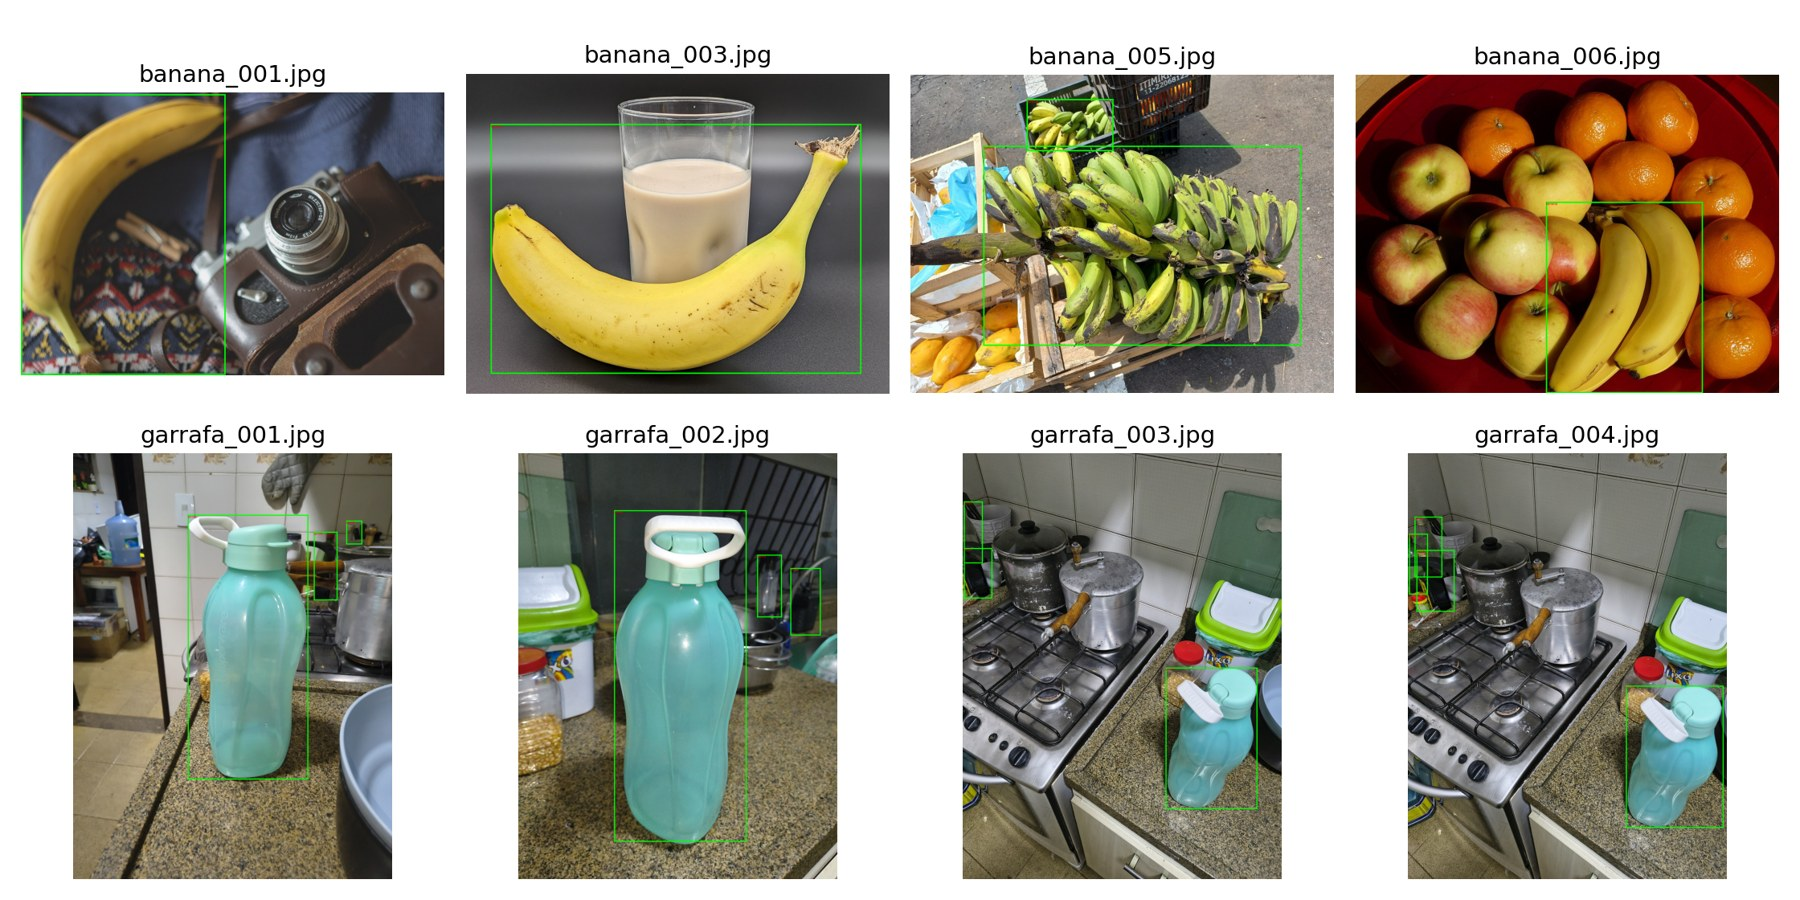

In [4]:
# Converter as caixas YOLO normalizadas em pixels permite conferir visualmente os rótulos.
def draw_reference(path):
    image = Image.open(path).convert("RGB")
    draw = ImageDraw.Draw(image)
    labels = DATA / "labels" / Path(path).parent.name / (Path(path).stem + ".txt")
    for line in labels.read_text().splitlines():
        if not line.strip():
            continue
        class_id, x, y, w, h = map(float, line.split())
        corners = [(x-w/2)*image.width, (y-h/2)*image.height,
                   (x+w/2)*image.width, (y+h/2)*image.height]
        draw.rectangle(corners, outline="lime", width=max(2, image.width // 300))
        draw.text((max(0, corners[0]), max(0, corners[1])), CLASSES[int(class_id)], fill="red")
    return image

examples = manifest[manifest.split == "train"].groupby("class_id").head(4)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    ax.imshow(draw_reference(row.path)); ax.set_title(row.arquivo); ax.axis("off")
show_saved_figure(fig, "amostras_rotuladas.png", dpi=160)


## 4. YOLOv5: dois experimentos independentes
Cada execução começa em `yolov5s.pt`; o treino de 60 épocas não continua o de 30.
`patience=0` desativa parada antecipada para preservar os dois orçamentos completos.
O checkpoint `best.pt` é escolhido pelo critério interno de validação do YOLOv5.
Na comparação entre experimentos, usamos mAP@0.5:0.95 de validação, com desempate a favor de 30 épocas.

O agendamento da taxa de aprendizado depende do total de épocas; portanto, comparar 30 e 60
significa comparar dois orçamentos de treinamento, não apenas copiar a trajetória das 30 primeiras épocas.
Os tempos incluem a execução do script, validação interna e gravação de artefatos.

In [5]:
INITIAL_WEIGHTS = WORK / "yolov5s.pt"
if not INITIAL_WEIGHTS.exists():
    urlretrieve("https://github.com/ultralytics/yolov5/releases/download/v7.0/yolov5s.pt", INITIAL_WEIGHTS)
initial_sha = hashlib.sha256(INITIAL_WEIGHTS.read_bytes()).hexdigest()
training_times = {}
for epochs in EPOCHS:
    start = time.perf_counter()
    run_command([sys.executable, REPO / "train.py", "--data", DATA_YAML,
                 "--weights", INITIAL_WEIGHTS, "--img", IMAGE_SIZE,
                 "--batch-size", BATCH_SIZE, "--epochs", epochs,
                 "--seed", SEED, "--workers", 2, "--device", DEVICE,
                 "--patience", 0, "--project", OUT / "treinos", "--name", f"yolo_{epochs}"], cwd=REPO)
    training_times[epochs] = time.perf_counter() - start
    weights_path = OUT / "treinos" / f"yolo_{epochs}" / "weights" / "best.pt"
    if not weights_path.is_file():
        raise FileNotFoundError("Treino sem best.pt: " + str(weights_path))
    history = pd.read_csv(weights_path.parents[1] / "results.csv")
    if len(history) != epochs:
        raise RuntimeError(f"Treino incompleto: {len(history)} de {epochs} épocas.")
(OUT / "tempos_treino.json").write_text(json.dumps(training_times, indent=2), encoding="utf-8")
(OUT / "pesos_iniciais_sha256.txt").write_text(initial_sha, encoding="utf-8")
display(pd.DataFrame([{"epocas": e, "tempo_treino_s": training_times[e]} for e in EPOCHS]))


,epocas,tempo_treino_s
0,30,226.845311
1,60,350.380825


### Curvas: desempenho e erro
A perda de treino pode continuar caindo enquanto a validação piora: isso sugere sobreajuste.
As perdas de caixa, objeto e classe têm funções diferentes; não comparar seus valores absolutos
com a entropia cruzada da CNN. As curvas são evidência de aprendizado, não prova de generalização.

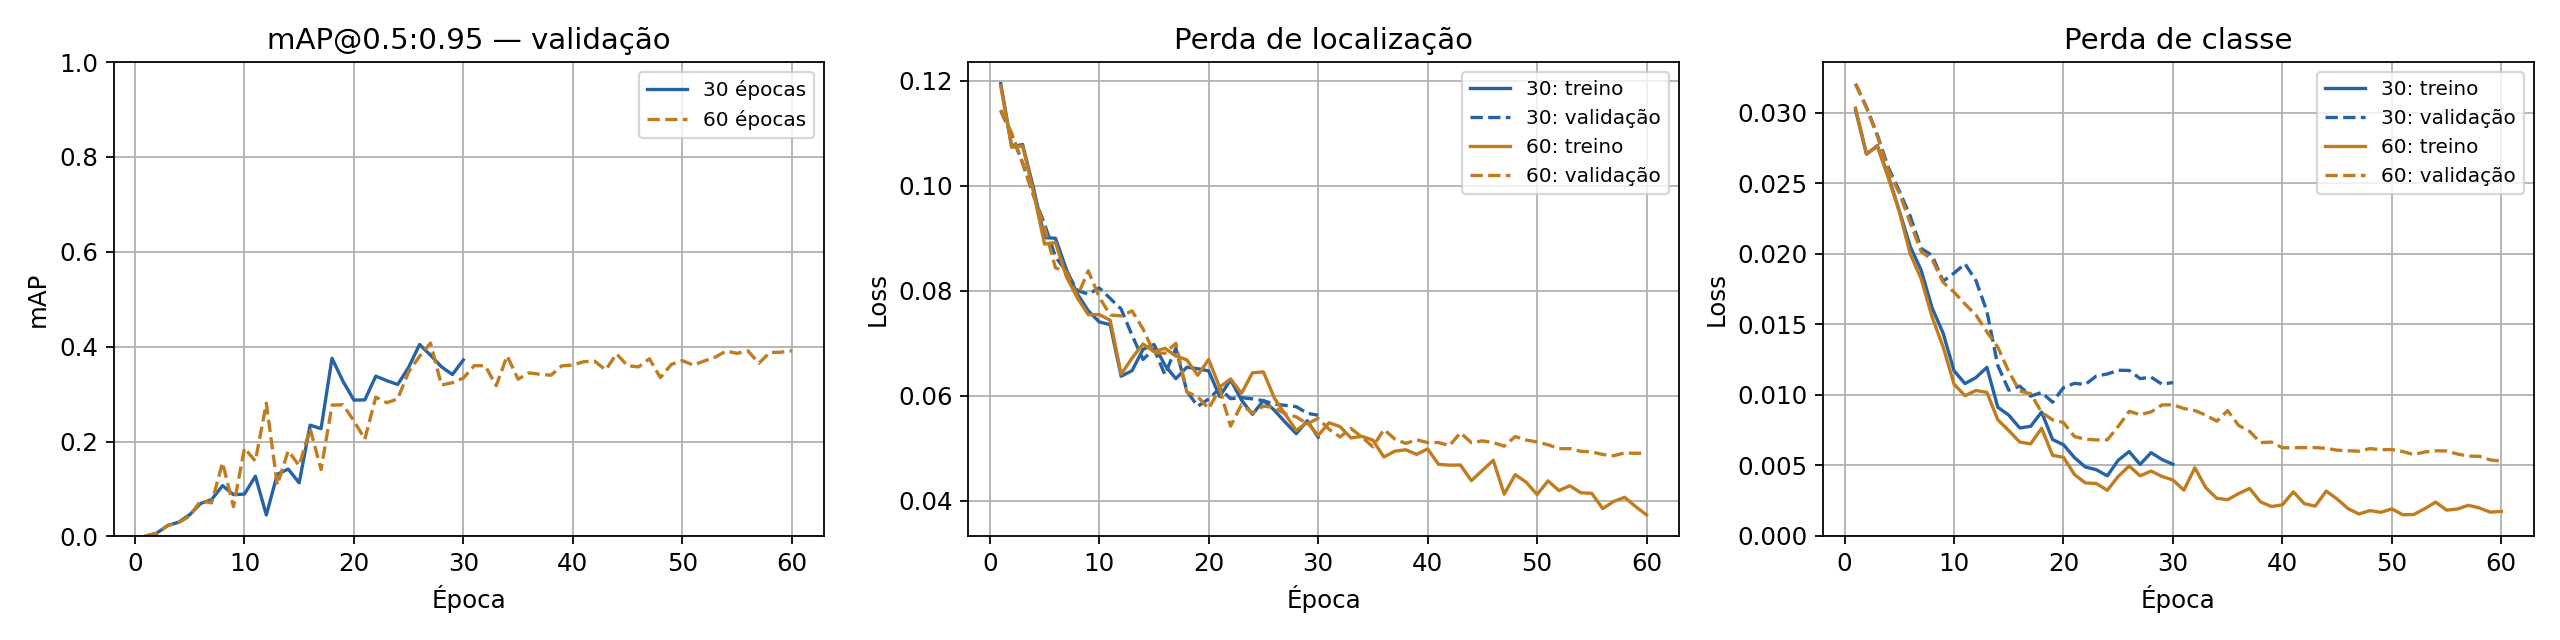

In [6]:
# Comparar curvas por época ajuda a detectar sobreajuste; a escolha final usa a validação.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for epochs in EPOCHS:
    history = pd.read_csv(OUT / "treinos" / f"yolo_{epochs}" / "results.csv")
    history.columns = history.columns.str.strip()
    x = np.arange(1, len(history) + 1)
    color = EPOCH_COLORS[epochs]
    axes[0].plot(x, history["metrics/mAP_0.5:0.95"], color=color,
                 linestyle="-" if epochs == 30 else "--", label=f"{epochs} épocas")
    axes[1].plot(x, history["train/box_loss"], color=color, label=f"{epochs}: treino")
    axes[1].plot(x, history["val/box_loss"], color=color, linestyle="--", label=f"{epochs}: validação")
    axes[2].plot(x, history["train/cls_loss"], color=color, label=f"{epochs}: treino")
    axes[2].plot(x, history["val/cls_loss"], color=color, linestyle="--", label=f"{epochs}: validação")
for ax, title in zip(axes, ["mAP@0.5:0.95 — validação", "Perda de localização", "Perda de classe"]):
    ax.set_title(title); ax.set_xlabel("Época"); ax.legend(fontsize=9)
axes[0].set_ylim(0, 1); axes[0].set_ylabel("mAP")
axes[1].set_ylabel("Loss"); axes[2].set_ylabel("Loss")
show_saved_figure(fig, "comparacao_epocas.png", dpi=160)


### Validação independente dos checkpoints
Precision mede a proporção de detecções positivas corretas; recall mede a recuperação dos objetos.
mAP resume curvas precisão–recall levando em conta a sobreposição das caixas (IoU).
O limiar baixo de confiança na avaliação preserva candidatos para calcular a curva de AP.
O limiar de demonstração/classificação por imagem permanece fixo em 0,25.

In [7]:
# Importar a implementação oficial a partir da revisão local fixada.
sys.path.insert(0, str(REPO))
from val import run as evaluate_yolov5

detection_records = []
for epochs in EPOCHS:
    metrics, per_class, speeds = evaluate_yolov5(
        data=str(DATA_YAML), weights=str(OUT / "treinos" / f"yolo_{epochs}" / "weights" / "best.pt"),
        task="val", imgsz=IMAGE_SIZE, batch_size=BATCH_SIZE, device=DEVICE,
        workers=2, half=False, conf_thres=0.001, iou_thres=0.6,
        project=str(OUT / "avaliacoes"), name=f"val_{epochs}", plots=True)
    detection_records.append({"split": "val", "epocas": epochs,
        "precision": metrics[0], "recall": metrics[1], "mAP50": metrics[2],
        "mAP50_95": metrics[3], "tempo_treino_s": training_times[epochs]})
validation_table = pd.DataFrame(detection_records)
display(validation_table.round(4))
SELECTED_EPOCHS = int(validation_table.sort_values(["mAP50_95", "epocas"], ascending=[False, True]).iloc[0].epocas)
(OUT / "selecao_validacao.json").write_text(json.dumps({"epocas": SELECTED_EPOCHS,
    "criterio": "maior mAP50_95 de validacao; desempate menor numero de epocas"}), encoding="utf-8")
print("Modelo selecionado pela validação:", SELECTED_EPOCHS, "épocas. Não trocar após observar o teste.")


YOLOv5 🚀 v7.0-551-g2b1bdcd0 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/farmtech_fase6/dataset_20261013T005458935971Z/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.3s/it 1.3s
                   all          8         21      0.837      0.539      0.577      0.405
               garrafa          8         16      0.792      0.478      0.458       0.34
                banana          8          5      0.882        0.6      0.696       0.47
Speed: 0.5ms pre-process, 22.9ms inference, 34.7ms NMS per image at shape (8, 3, 640, 640)
Results saved to /content/drive/MyDrive/FarmTechFase6/resultados/20261013T005458935971Z/avaliacoes/val_30
YOLOv5 🚀 v7.0-551-g2b1bdcd0 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers.

,split,epocas,precision,recall,mAP50,mAP50_95,tempo_treino_s
0,val,30,0.8369,0.5388,0.577,0.4047,226.8453
1,val,60,0.6937,0.6188,0.622,0.4073,350.3808


Modelo selecionado pela validação: 60 épocas. Não trocar após observar o teste.


### Seleção nesta rodada

| Conjunto | Épocas | mAP@0,5 | mAP@0,5:0,95 |
|---|---:|---:|---:|
| val | 30 | 0.5770 | 0.4047 |
| val | 60 | 0.6220 | 0.4073 |
| test | 30 | 0.8414 | 0.5239 |
| test | 60 | 0.6636 | 0.3615 |

O experimento de 60 épocas foi escolhido pela maior mAP@0,5:0,95 de validação. Os resultados de teste são apenas relatados; não alteraram a seleção.

## 5. CNN treinada do zero
Arquitetura pequena com três blocos convolucionais, pooling, média global, dropout e saída softmax.
Os pesos começam aleatórios. Aumentos aleatórios atuam apenas no treino; a normalização faz parte
do modelo. A seleção do checkpoint usa `val_loss`, sem qualquer acesso ao teste.

A CNN é treinada em CPU para limitar competição de memória com PyTorch neste notebook pequeno.
O custo de treino deve ser interpretado junto com o hardware registrado: não é uma comparação
isolada de velocidade de arquitetura com o YOLO, que pode ter sido treinado em GPU.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,714 (92.63 KB)

 Trainable params: 23,714 (92.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
8/8 - 4s - 560ms/step - accuracy: 0.4531 - loss: 0.6914 - val_accuracy: 0.6250 - val_loss: 0.6945
Epoch 2/30
8/8 - 1s - 169ms/step - accuracy: 0.5312 - loss: 0.6754 - val_accuracy: 0.5000 - val_loss: 0.6968
Epoch 3/30
8/8 - 1s - 127ms/step - accuracy: 0.5469 - loss: 0.6495 - val_accuracy: 0.6250 - val_loss: 0.7066
Epoch 4/30
8/8 - 1s - 127ms/step - accuracy: 0.6406 - loss: 0.6200 - val_accuracy: 0.5000 - val_loss: 0.7310
Epoch 5/30
8/8 - 1s - 128ms/step - accuracy: 0.7812 - loss: 0.5681 - val_accuracy: 0.5000 - val_loss: 0.7977
Epoch 6/30
8/8 - 1s - 127ms/step - accuracy: 0.7344 - loss: 0.5416 - val_accuracy: 0.5000 - val_loss: 0.8785
Epoch 7/30
8/8 - 1s - 125ms/step - accuracy: 0.8281 - loss: 0.4609 - val_accuracy: 0.5000 - val_loss: 1.0890


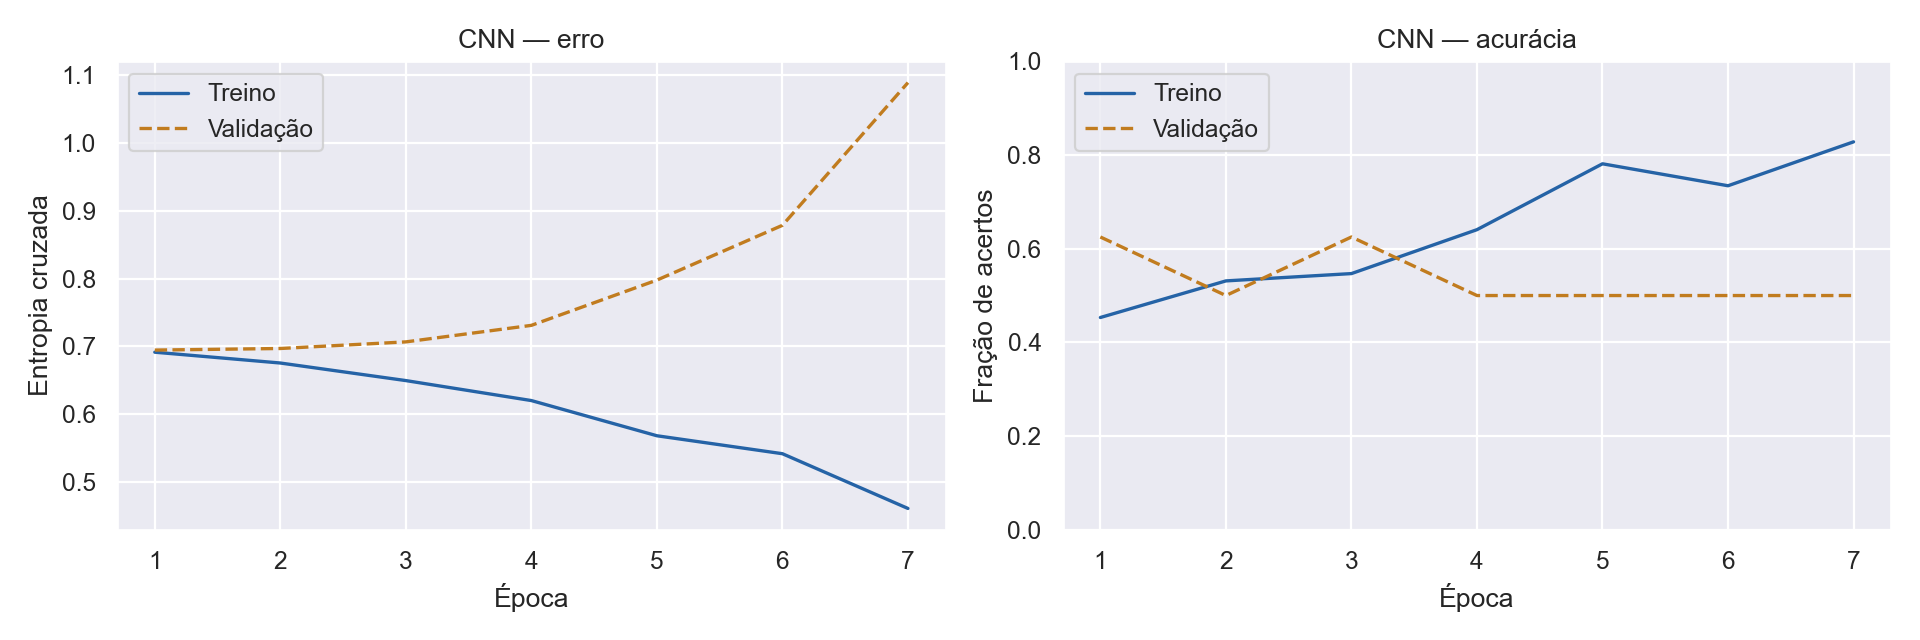

In [8]:
# A CNN é treinada do zero em CPU; validação seleciona pesos, e teste permanece reservado.
import tensorflow as tf
tf.config.set_visible_devices([], "GPU")
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
CNN_SIZE = 128

def load_classification_split(split):
    rows = manifest[manifest.split == split].sort_values("arquivo")
    images = []
    for path in rows.path:
        with Image.open(path) as image:
            images.append(np.asarray(image.convert("RGB").resize((CNN_SIZE, CNN_SIZE)), dtype=np.float32))
    # O manifesto fornece uma classe por imagem (0/1), diferente das caixas de detecção.
    return np.stack(images), rows.class_id.to_numpy(), rows

x_train, y_train, _ = load_classification_split("train")
x_val, y_val, _ = load_classification_split("val")
cnn = tf.keras.Sequential([
    tf.keras.layers.Input((CNN_SIZE, CNN_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3, seed=SEED),
    tf.keras.layers.Dense(2, activation="softmax"),
])
cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()
CNN_PATH = OUT / "cnn_do_zero.keras"
start = time.perf_counter()
cnn_history = cnn.fit(x_train, y_train, validation_data=(x_val, y_val),
    epochs=30, batch_size=8, shuffle=True, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
               tf.keras.callbacks.ModelCheckpoint(str(CNN_PATH), monitor="val_loss", save_best_only=True)])
cnn_train_s = time.perf_counter() - start
# Recuperar o checkpoint de menor perda de validação, não os pesos da última época.
cnn = tf.keras.models.load_model(CNN_PATH)
cnn_curve = pd.DataFrame(cnn_history.history)
cnn_curve.to_csv(OUT / "cnn_historico.csv", index=False)
(OUT / "cnn_configuracao.json").write_text(json.dumps({"tensorflow": tf.__version__,
    "device": "CPU", "epocas_executadas": len(cnn_curve), "tempo_treino_s": cnn_train_s,
    "epoca_menor_val_loss": int(cnn_curve.val_loss.idxmin() + 1), "parametros": cnn.count_params()}, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, color, label, style in [("", "#2563a6", "Treino", "-"), ("val_", "#c17c1f", "Validação", "--")]:
    axes[0].plot(np.arange(1, len(cnn_curve)+1), cnn_curve[key+"loss"], color=color, linestyle=style, label=label)
    axes[1].plot(np.arange(1, len(cnn_curve)+1), cnn_curve[key+"accuracy"], color=color, linestyle=style, label=label)
for ax, title, ylabel in zip(axes, ["CNN — erro", "CNN — acurácia"], ["Entropia cruzada", "Fração de acertos"]):
    ax.set_title(title); ax.set_xlabel("Época"); ax.set_ylabel(ylabel); ax.legend()
axes[1].set_ylim(0, 1)
show_saved_figure(fig, "cnn_curvas.png", dpi=160)


## 6. YOLOv3 padrão e classificação comparável entre abordagens
O YOLOv3 utiliza os pesos originais COCO, sem customização. É a arquitetura do exemplo dos
materiais da disciplina; aqui sua inferência usa OpenCV DNN, evitando compilar Darknet no Colab.
Essa diferença de integração deve ser informada no relatório e no vídeo.

Para a comparação por imagem, o detector escolhe a classe da detecção-alvo de maior confiança
após supressão de caixas sobrepostas; se não houver alvo acima de 0,25, retorna **sem detecção**,
contabilizada como erro. Classes COCO fora das duas classes do estudo são ignoradas.
A CNN escolhe a maior probabilidade softmax e sempre retorna uma classe. Essa assimetria faz
parte do comportamento das soluções e deve ser discutida.

O limiar foi fixado antes do teste; não ajustá-lo para melhorar o resultado nas 8 imagens reservadas.


**Ajuste operacional observado:** o endereço antigo dos pesos retornou HTTP 403. O download foi corrigido para `https://data.pjreddie.com/files/yolov3.weights`, indicado pelo projeto oficial, com cabeçalho `User-Agent`, arquivo temporário e substituição apenas após concluir a transferência. A origem e o SHA-256 dos arquivos efetivamente usados estão em `yolov3_fontes_e_hashes.json`.

In [9]:
import cv2
cv2.setNumThreads(1)
torch.set_num_threads(1)
YOLO3 = WORK / "yolov3"
YOLO3.mkdir(exist_ok=True)
downloads = {
    "yolov3.cfg": "https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg",
    "coco.names": "https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names",
    "yolov3.weights": "https://data.pjreddie.com/files/yolov3.weights",
}
for filename, url in downloads.items():
    target = YOLO3 / filename
    if not target.exists():
        print("Baixando:", filename, url, flush=True)
        from urllib.request import Request, urlopen
        request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
        temporary = target.with_suffix(target.suffix + ".part")
        with urlopen(request, timeout=90) as response, temporary.open("wb") as output:
            shutil.copyfileobj(response, output)
        temporary.replace(target)
coco_labels = (YOLO3 / "coco.names").read_text().splitlines()
if any(name not in coco_labels for name in COCO_NAMES):
    raise ValueError("Classe-alvo ausente do YOLOv3 COCO; revisar a escolha dos objetos.")
coco_to_local = {coco_labels.index(name): i for i, name in enumerate(COCO_NAMES)}
network = cv2.dnn.readNetFromDarknet(str(YOLO3 / "yolov3.cfg"), str(YOLO3 / "yolov3.weights"))
network.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
network.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
standard = cv2.dnn_DetectionModel(network)
standard.setInputParams(scale=1/255, size=(416, 416), swapRB=True, crop=False)

def predict_yolov3(rgb):
    ids, scores, boxes = standard.detect(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR),
                                         confThreshold=CONFIDENCE, nmsThreshold=NMS_IOU)
    detections = []
    for class_id, score, box in zip(np.asarray(ids).reshape(-1), np.asarray(scores).reshape(-1), boxes):
        if int(class_id) in coco_to_local:
            x, y, w, h = map(float, box)
            detections.append([x, y, x+w, y+h, float(score), coco_to_local[int(class_id)]])
    # Comparação por imagem: classe-alvo de maior confiança; -1 significa nenhuma detecção.
    if not detections:
        return -1, 0.0, []
    best = max(detections, key=lambda row: row[4])
    return int(best[5]), float(best[4]), detections

# Os dois checkpoints ficam em CPU para a comparação de inferência no mesmo hardware.
yolo_models = {}
for epochs in EPOCHS:
    weights_path = OUT / "treinos" / f"yolo_{epochs}" / "weights" / "best.pt"
    model = torch.hub.load(str(REPO), "custom", path=str(weights_path), source="local", device="cpu")
    model.conf, model.iou = CONFIDENCE, NMS_IOU
    model.eval()
    yolo_models[epochs] = model

def make_yolo_predictor(model):
    def predict(rgb):
        with torch.inference_mode():
            rows = model(rgb, size=IMAGE_SIZE).xyxy[0].cpu().numpy().tolist()
        if not rows:
            return -1, 0.0, []
        best = max(rows, key=lambda row: row[4])
        return int(best[5]), float(best[4]), rows
    return predict

def predict_cnn(rgb):
    resized = np.asarray(Image.fromarray(rgb).resize((CNN_SIZE, CNN_SIZE)), dtype=np.float32)
    probabilities = cnn(resized[None, ...], training=False).numpy()[0]
    return int(np.argmax(probabilities)), float(np.max(probabilities)), []

predictors = {f"YOLOv5_{e}": make_yolo_predictor(yolo_models[e]) for e in EPOCHS}
predictors.update({"YOLOv3_padrao": predict_yolov3, "CNN_do_zero": predict_cnn})
asset_hashes = {filename: hashlib.sha256((YOLO3 / filename).read_bytes()).hexdigest() for filename in downloads}
(OUT / "yolov3_fontes_e_hashes.json").write_text(json.dumps({"urls": downloads, "sha256": asset_hashes}, indent=2))


Baixando: yolov3.cfg https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg
Baixando: coco.names https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names
Baixando: yolov3.weights https://data.pjreddie.com/files/yolov3.weights
YOLOv5 🚀 v7.0-551-g2b1bdcd0 Python-3.13.15 torch-2.11.0+cu130 CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-551-g2b1bdcd0 Python-3.13.15 torch-2.11.0+cu130 CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 


559

### Comparação por imagem na validação
Usar as mesmas imagens e a mesma convenção de classe. F1 macro atribui o mesmo peso às duas
classes. A ausência de detecção reduz recall e acurácia; não excluir esses casos da tabela.


O F1 macro é a média somente das duas classes-alvo (`garrafa` e `banana`); a ausência de detecção gera falso negativo para a classe real, sem receber uma terceira parcela na média. Portanto, F1 macro e acurácia não são intercambiáveis: por exemplo, um detector sem confusões entre classes ainda perde acurácia e recall quando se abstém.

In [10]:
# As mesmas imagens e classes são usadas nos quatro modelos, incluindo ausências de detecção.
prediction_rows, cached_predictions = [], {}

def evaluate_classification(split):
    for name, predictor in predictors.items():
        for row in manifest[manifest.split == split].sort_values("arquivo").itertuples():
            with Image.open(row.path) as image:
                rgb = np.asarray(image.convert("RGB"))
            predicted, score, boxes = predictor(rgb)
            prediction_rows.append({"modelo": name, "split": split, "arquivo": row.arquivo,
                                    "real": row.class_id, "previsto": predicted, "score": score})
            cached_predictions[(name, split, row.arquivo)] = boxes

def classification_summary(frame):
    records = []
    for (name, split), part in frame.groupby(["modelo", "split"]):
        # -1 conta como erro na acurácia e falso negativo no recall da classe real.
        precision, recall, f1, _ = precision_recall_fscore_support(
            part.real, part.previsto, labels=[0, 1], average="macro", zero_division=0)
        records.append({"modelo": name, "split": split, "n": len(part),
            "acertos": int((part.real == part.previsto).sum()),
            "sem_deteccao": int((part.previsto == -1).sum()),
            "acuracia": accuracy_score(part.real, part.previsto),
            "precision_macro": precision, "recall_macro": recall, "F1_macro": f1})
    return pd.DataFrame(records)

evaluate_classification("val")
display(classification_summary(pd.DataFrame(prediction_rows)).round(4))


,modelo,split,n,acertos,sem_deteccao,acuracia,precision_macro,recall_macro,F1_macro
0,CNN_do_zero,val,8,5,0,0.625,0.7857,0.625,0.5636
1,YOLOv3_padrao,val,8,6,2,0.750,1.0000,0.750,0.8571
2,YOLOv5_30,val,8,7,1,0.875,1.0000,0.875,0.9286
3,YOLOv5_60,val,8,8,0,1.000,1.0000,1.000,1.0000


## 7. Avaliação final no teste reservado
O protocolo, os hiperparâmetros e o YOLOv5 selecionado já foram definidos antes desta etapa.
Relatamos os dois orçamentos no teste porque a atividade pede a comparação, mas não usamos
esses resultados para trocar a seleção, repetir ajustes ou escolher o melhor limiar.

Com 8 imagens de teste, um acerto equivale a **12,5 pontos percentuais** de acurácia.
Repetir inferências para medir tempo não aumenta o número de imagens independentes.
O conjunto é pequeno demais para alegações de desempenho em produção.

In [11]:
# O teste só é consultado após fixar SELECTED_EPOCHS pela validação; não refazer essa seleção.
for epochs in EPOCHS:
    metrics, per_class, speeds = evaluate_yolov5(
        data=str(DATA_YAML), weights=str(OUT / "treinos" / f"yolo_{epochs}" / "weights" / "best.pt"),
        task="test", imgsz=IMAGE_SIZE, batch_size=BATCH_SIZE, device=DEVICE,
        workers=2, half=False, conf_thres=0.001, iou_thres=0.6,
        project=str(OUT / "avaliacoes"), name=f"test_{epochs}", plots=True)
    detection_records.append({"split": "test", "epocas": epochs,
        "precision": metrics[0], "recall": metrics[1], "mAP50": metrics[2],
        "mAP50_95": metrics[3], "tempo_treino_s": training_times[epochs]})
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
detection_table = pd.DataFrame(detection_records)
detection_table.to_csv(OUT / "metricas_deteccao.csv", index=False)
display(detection_table.round(4))

evaluate_classification("test")
predictions = pd.DataFrame(prediction_rows)
summary = classification_summary(predictions)
predictions.to_csv(OUT / "predicoes_por_imagem.csv", index=False)
summary.to_csv(OUT / "comparacao_classificacao.csv", index=False)
display(summary.round(4))


YOLOv5 🚀 v7.0-551-g2b1bdcd0 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/farmtech_fase6/dataset_20261013T005458935971Z/labels/test... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 513.4it/s 0.0s
test: New cache created: /content/farmtech_fase6/dataset_20261013T005458935971Z/labels/test.cache
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.5it/s 0.6s
                   all          8         12      0.924      0.688      0.841      0.524
               garrafa          8          8      0.895      0.875      0.875      0.544
                banana          8          4      0.953        0.5      0.808      0.504
Speed: 0.3ms pre-process, 12.0ms inference, 4.3ms NMS per image at shape (8, 3, 640, 640)
Results saved to /content/drive/MyDrive/FarmTechFase6/resultados/20261013T005458

,split,epocas,precision,recall,mAP50,mAP50_95,tempo_treino_s
0,val,30,0.8369,0.5388,0.5770,0.4047,226.8453
1,val,60,0.6937,0.6188,0.6220,0.4073,350.3808
2,test,30,0.9235,0.6875,0.8414,0.5239,226.8453
3,test,60,0.5800,0.6875,0.6636,0.3615,350.3808


,modelo,split,n,acertos,sem_deteccao,acuracia,precision_macro,recall_macro,F1_macro
0,CNN_do_zero,test,8,5,0,0.625,0.7857,0.625,0.5636
1,CNN_do_zero,val,8,5,0,0.625,0.7857,0.625,0.5636
2,YOLOv3_padrao,test,8,7,1,0.875,1.0000,0.875,0.9286
3,YOLOv3_padrao,val,8,6,2,0.750,1.0000,0.750,0.8571
4,YOLOv5_30,test,8,6,1,0.750,0.8750,0.750,0.8036
5,YOLOv5_30,val,8,7,1,0.875,1.0000,0.875,0.9286
6,YOLOv5_60,test,8,4,4,0.500,1.0000,0.500,0.6667
7,YOLOv5_60,val,8,8,0,1.000,1.0000,1.000,1.0000


### Erros por classe
A matriz contém duas linhas reais e três colunas previstas: as duas classes e ausência de detecção.
Para a CNN, a última coluna será zero por definição. O gráfico mantém escalas iguais entre modelos.

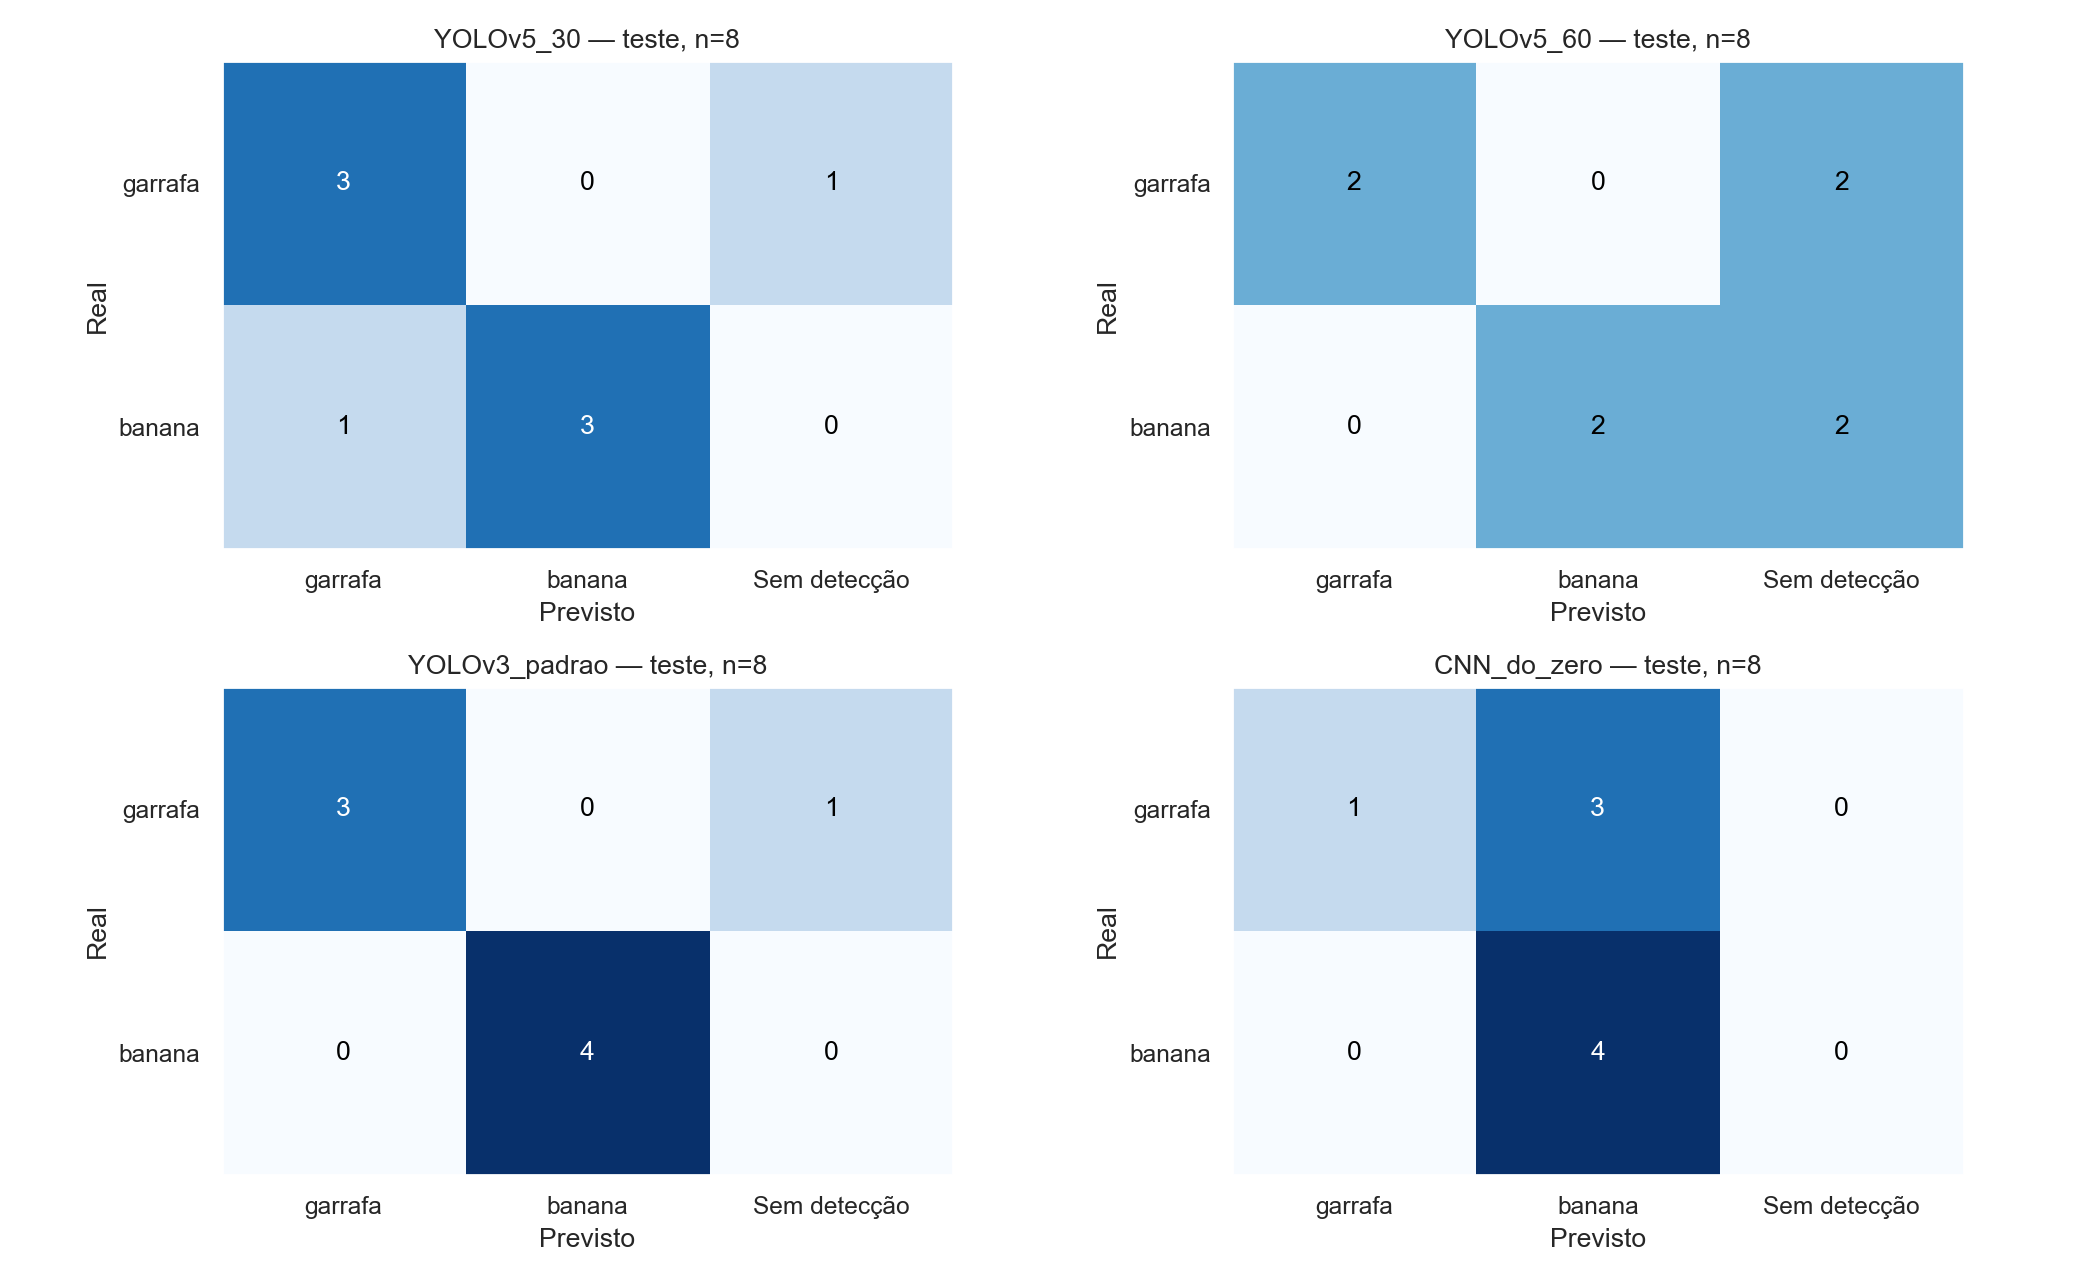

In [12]:
# A terceira coluna registra a abstenção (-1), sem criar uma terceira classe real.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, name in zip(axes.flat, predictors):
    part = predictions[(predictions.modelo == name) & (predictions.split == "test")]
    matrix = confusion_matrix(part.real, part.previsto, labels=[0, 1, -1])[:2, :]
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=4)
    ax.set_xticks(range(3), CLASSES + ["Sem detecção"])
    ax.set_yticks(range(2), CLASSES)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title(name + " — teste, n=8")
    ax.grid(False)
    for (r, c), count in np.ndenumerate(matrix):
        ax.text(c, r, str(count), ha="center", va="center", color="white" if count > 2 else "black")
show_saved_figure(fig, "matrizes_confusao_teste.png", dpi=160)


### Evidências visuais: todas as imagens de teste
Exibir as 8 imagens, inclusive falhas. As caixas são previsões; o título informa a classe real
e a classe atribuída. A confiança de uma caixa não é a acurácia do modelo.
As imagens individuais exportadas podem ser usadas como prints na entrega e na demonstração.

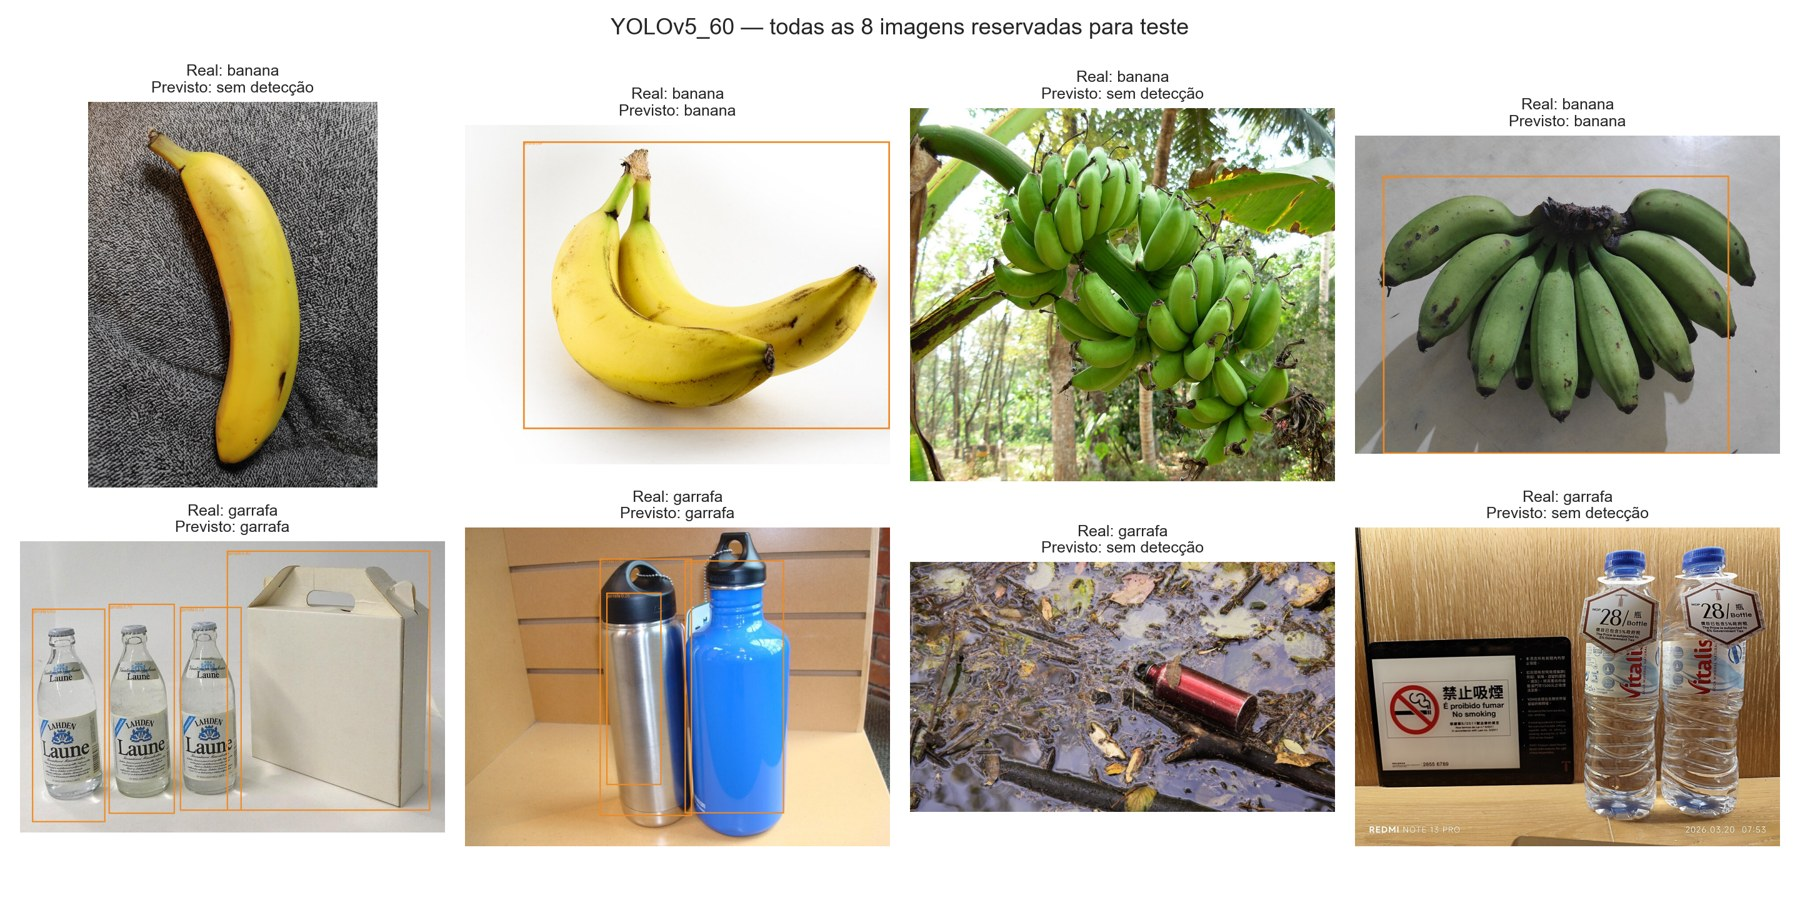

In [13]:
# Mostrar todas as oito imagens evita escolher apenas exemplos favoráveis ao modelo selecionado.
selected_name = f"YOLOv5_{SELECTED_EPOCHS}"
EVIDENCE = OUT / "imagens_teste"
EVIDENCE.mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.flat, manifest[manifest.split == "test"].sort_values("arquivo").itertuples()):
    image = Image.open(row.path).convert("RGB")
    draw = ImageDraw.Draw(image)
    for x1, y1, x2, y2, score, class_id in cached_predictions[(selected_name, "test", row.arquivo)]:
        draw.rectangle([x1, y1, x2, y2], outline="#ef8a24", width=max(2, image.width // 250))
        draw.text((max(0, x1), max(0, y1)), f"{CLASSES[int(class_id)]} {score:.2f}", fill="#ef8a24")
    result = predictions[(predictions.modelo == selected_name) & (predictions.split == "test") & (predictions.arquivo == row.arquivo)].iloc[0]
    label = CLASSES[int(result.previsto)] if result.previsto >= 0 else "sem detecção"
    image.save(EVIDENCE / (Path(row.arquivo).stem + "_predicao.jpg"))
    ax.imshow(image); ax.set_title(f"Real: {row.classe}\nPrevisto: {label}", fontsize=10); ax.axis("off")
fig.suptitle(selected_name + " — todas as 8 imagens reservadas para teste")
show_saved_figure(fig, "painel_teste.png", dpi=180)


## 8. Tempo de inferência no mesmo ambiente
Comparação em CPU, uma thread por biblioteca, lote de uma imagem, três aquecimentos e cinco
repetições por imagem. O intervalo medido inclui preparação da imagem, rede e pós-processamento;
exclui leitura de arquivo, carregamento do modelo e gravação de prints.
YOLOv5 usa entrada-alvo 640, YOLOv3 usa 416 e CNN usa 128 pixels. Assim, medimos estas configurações
de solução; não isolamos o efeito da arquitetura. Reportar mediana e percentil 95, sem prometer
os mesmos tempos em outro computador. O treino do YOLOv3 é não aplicável neste projeto.

In [14]:
# Carregar imagens antes de cronometrar exclui leitura de disco, mas mantém pré/pós-processamento.
test_images = []
for path in manifest[manifest.split == "test"].sort_values("arquivo").path:
    with Image.open(path) as image:
        test_images.append(np.asarray(image.convert("RGB")))
timing_records = []
for name, predictor in predictors.items():
    # Aquecer o modelo e medir 5 repetições x 8 imagens na mesma CPU.
    for _ in range(3):
        predictor(test_images[0])
    for repetition in range(5):
        for i, rgb in enumerate(test_images):
            start = time.perf_counter()
            predictor(rgb)
            elapsed_ms = (time.perf_counter() - start) * 1000
            timing_records.append({"modelo": name, "repeticao": repetition, "imagem": i, "tempo_ms": elapsed_ms})
timings = pd.DataFrame(timing_records)
timings.to_csv(OUT / "tempos_inferencia_brutos.csv", index=False)
latencies = timings.groupby("modelo").tempo_ms.agg(
    mediana_ms="median", p95_ms=lambda s: s.quantile(0.95)).reset_index()
comparison = summary[summary.split == "test"].merge(latencies, on="modelo")
costs = {f"YOLOv5_{e}": training_times[e] for e in EPOCHS}
costs.update({"CNN_do_zero": cnn_train_s, "YOLOv3_padrao": np.nan})
comparison["tempo_treino_s"] = comparison.modelo.map(costs)
comparison.to_csv(OUT / "comparacao_final.csv", index=False)
display(comparison.round(4))
print("NaN em tempo de treino do YOLOv3 = não aplicável; o pré-treino externo não foi medido.")


,modelo,split,n,acertos,sem_deteccao,...,recall_macro,F1_macro,mediana_ms,p95_ms,tempo_treino_s
0,CNN_do_zero,test,8,5,0,...,0.625,0.5636,40.6494,61.0641,11.0016
1,YOLOv3_padrao,test,8,7,1,...,0.875,0.9286,1046.5465,1276.6792,NaN
2,YOLOv5_30,test,8,6,1,...,0.750,0.8036,195.2112,283.8621,226.8453
3,YOLOv5_60,test,8,4,4,...,0.500,0.6667,177.1114,221.8907,350.3808


NaN em tempo de treino do YOLOv3 = não aplicável; o pré-treino externo não foi medido.


## Resultados desta verificação

O critério de validação selecionou o experimento de **60 épocas**; essa escolha foi mantida no teste. Os históricos contêm 30 e 60 épocas completas.

| Conjunto | Épocas | mAP@0,5 | mAP@0,5:0,95 |
|---|---:|---:|---:|
| val | 30 | 0.5770 | 0.4047 |
| val | 60 | 0.6220 | 0.4073 |
| test | 30 | 0.8414 | 0.5239 |
| test | 60 | 0.6636 | 0.3615 |

| Modelo | Acertos no teste | Sem detecção | Mediana CPU (ms) |
|---|---:|---:|---:|
| CNN_do_zero | 5/8 | 0 | 40.65 |
| YOLOv3_padrao | 7/8 | 1 | 1046.55 |
| YOLOv5_30 | 6/8 | 1 | 195.21 |
| YOLOv5_60 | 4/8 | 4 | 177.11 |

A CNN executou 7 épocas e restaurou a época 1, de menor perda de validação. Continua sendo uma classificadora com 23.714 parâmetros, sem localização de objetos. A comparação usa oito imagens de teste; ausências de detecção contam como erro.

Esta rodada serve para verificar a execução das correções, não para escolher um resultado mais favorável. O vídeo e a discussão principal permanecem vinculados à referência de 04/10. Variações nos YOLOv5 e nos tempos entre sessões não são evidência de melhora causada pela correção de exibição ou pelas versões fixadas; essa relação causal não foi testada. Repetições com a mesma divisão pequena não substituem testes independentes nem demonstram desempenho de produção.


## 10. Preservação e escopo

Os resultados desta sessão estão no [ZIP completo](https://github.com/teteuriscado-bot/MatheusSilvaRiscado/releases/download/fase6-2026-10-04/RESULTADOS-FARMTECH-20261013T005458935971Z.zip) e os hashes em `VERIFICACAO.json`. A cópia original do notebook foi preservada. Os resultados de 04/10 continuam sendo a referência do notebook principal e do vídeo. Nenhum gráfico desta rodada precisou ser acrescentado manualmente às saídas.

O uso acadêmico continua limitado pela base pequena, por imagens públicas possivelmente presentes no pré-treino externo e por uma única seed; não houve ampliação da base nem seleção posterior de hiperparâmetros.

In [15]:
# Falhar antes da exportação se algum resultado obrigatório não tiver sido produzido.
expected_outputs = ["manifesto_auditado.csv", "comparacao_epocas.png", "cnn_curvas.png",
    "metricas_deteccao.csv", "comparacao_classificacao.csv", "predicoes_por_imagem.csv",
    "comparacao_final.csv", "matrizes_confusao_teste.png", "painel_teste.png",
    "ambiente.json", "requirements-executados.txt", "requirements-colab.txt"]
missing = [name for name in expected_outputs if not (OUT / name).is_file()]
if missing:
    raise FileNotFoundError("Resultados faltantes: " + ", ".join(missing))
print("Artefatos calculados em:", OUT)
print("Revisar as conclusões e salvar o notebook COM AS SAÍDAS antes de publicar.")

# Preservar uma cópia portátil dos resultados, além da pasta no Drive.
archive = shutil.make_archive(str(WORK / ("RESULTADOS-FARMTECH-" + RUN_ID)), "zip", OUT)
if USE_DRIVE:
    # Preservar também o ZIP quando os resultados são salvos no Drive.
    shutil.copy2(archive, OUT.parent / Path(archive).name)
print("Arquivo de resultados:", archive)
from google.colab import files
files.download(archive)


Artefatos calculados em: /content/drive/MyDrive/FarmTechFase6/resultados/20261013T005458935971Z
Revisar as conclusões e salvar o notebook COM AS SAÍDAS antes de publicar.
Arquivo de resultados: /content/farmtech_fase6/RESULTADOS-FARMTECH-20261013T005458935971Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>